# TP F20 : Structure de la courbe des taux américaine par ACP

**Durée estimée :** 3 heures · **Niveau :** premier cycle universitaire, bases de Python, de statistique et de finance.

**Question de recherche :** trois facteurs suffisent-ils à décrire l'essentiel des mouvements de la courbe des taux américaine ?

## Objectifs

À la fin de ce TP, vous saurez :

1. reconnaître un problème d'apprentissage non supervisé et de réduction de dimension ;
2. charger, explorer et aligner cinq séries de taux FRED ;
3. calculer des variations journalières sans relier artificiellement deux périodes séparées ;
4. comparer une ACP à une composante avec une ACP à trois composantes ;
5. mesurer la variance expliquée et l'erreur de reconstruction ;
6. interpréter les axes comme des mouvements de niveau, de pente ou de courbure lorsque leurs profils le permettent ;
7. comparer l'ACP avec une analyse factorielle et examiner la stabilité selon la période.

**Organisation.** Comme le TP des manchots fourni en référence, ce document alterne explications, code Python, résultats et commentaires de lecture. Les méthodes sont adaptées au problème financier : il n'y a ni espèce à prédire, ni matrice de confusion.

**Exécution dans Colab.** Utiliser Fichier > Importer le notebook pour ouvrir ce fichier `.ipynb`. Déposer `F20_Donnees_FRED_ACP.xlsx` via le panneau Fichiers à gauche, puis exécuter les cellules dans l’ordre. Si le classeur est absent, le code tente un téléchargement FRED. Les résultats historiques reproduits dans les cellules de texte correspondent à l’exécution précédente et peuvent différer après une nouvelle récupération.

**Dépendances :** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `scipy`, `openpyxl`. Si nécessaire, les installer dans une cellule séparée avec `%pip install numpy pandas matplotlib seaborn scikit-learn scipy openpyxl`.

## 1. De quel type d'apprentissage s'agit-il ?

Chaque observation correspond à une date et comprend cinq rendements du Trésor américain. Nous cherchons quelques mouvements communs capables de résumer leurs variations.

Il s'agit d'**apprentissage non supervisé**, plus précisément de **réduction de dimension** : aucune variable cible $y$ ne fournit la « bonne réponse ». L'ACP construit des combinaisons linéaires des cinq variables qui conservent autant de variance que possible.

Passer de cinq maturités à trois composantes signifie représenter chaque séance par trois nombres plutôt que cinq. Cela ne revient pas à sélectionner trois maturités : chaque composante peut utiliser les cinq.

> **Distinction essentielle.** Ce TP décrit et reconstruit les variations observées. Il ne prévoit pas les taux du lendemain. Une bonne reconstruction ne constitue pas une stratégie de trading validée.

## 2. Le jeu de données

Source : **Board of Governors of the Federal Reserve System, publication H.15, diffusée par FRED**. Les taux sont quotidiens, exprimés en pourcentage annuel et non désaisonnalisés.

| Variable | Maturité | Type | Unité d'origine |
|---|---:|---|---|
| `DGS3MO` | 3 mois | numérique | % annuel |
| `DGS1` | 1 an | numérique | % annuel |
| `DGS5` | 5 ans | numérique | % annuel |
| `DGS10` | 10 ans | numérique | % annuel |
| `DGS30` | 30 ans | numérique | % annuel |

Le classeur fourni contient les feuilles `Guide`, `Variations_pb`, `Taux_alignes` et `Donnees_FRED`. Nous repartons de **`Donnees_FRED`**, afin de rendre le nettoyage et les différences visibles et reproductibles. Le fichier `DGS30.csv` seul ne permet pas une ACP sur cinq maturités.

**Attention à la période.** DGS30 commence en 1977, mais les cinq séries ne sont simultanément disponibles qu'à partir de septembre 1981 dans les fichiers reçus. FRED documente aussi une interruption de DGS30 du 18 février 2002 au 9 février 2006. Pourtant, le CSV et le classeur reçus contiennent des valeurs pendant cet intervalle. Leur statut n'étant pas résolu, l'analyse principale exclut cet intervalle par prudence, puis vérifie la sensibilité en le conservant. Ce filtre est explicite et ne modifie pas les fichiers sources.

### 2.1 Importation des bibliothèques

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.preprocessing import StandardScaler
from scipy.linalg import subspace_angles

np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
SERIES = ["DGS3MO", "DGS1", "DGS5", "DGS10", "DGS30"]
MATURITES = ["3 mois", "1 an", "5 ans", "10 ans", "30 ans"]
FIN_ETUDE = pd.Timestamp("2026-11-09")  # borne fixe, résultats reproductibles
RETIRER_INTERVALLE_DOCUMENTE = True
SEUIL = 0.95  # définition opérationnelle de « l'essentiel »
print("Version scikit-learn :", sklearn.__version__)

Version scikit-learn : 1.6.1


**Sortie obtenue sur les fichiers fournis :**

```text
Version scikit-learn : 1.8.0
```


### 2.2 Chargement depuis le fichier Excel, avec solution de repli FRED

Le fichier Excel est utilisé en priorité. Si celui-ci est absent, le code télécharge les cinq séries en une seule table. Les données FRED pouvant être révisées, une nouvelle récupération peut modifier légèrement les résultats.

In [2]:
fichier = Path(os.environ.get("F20_EXCEL", "F20_Donnees_FRED_ACP.xlsx"))
if fichier.exists():
    df = pd.read_excel(fichier, sheet_name="Donnees_FRED")
    origine = "Classeur fourni, feuille Donnees_FRED"
else:
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=" + ",".join(SERIES)
    df = pd.read_csv(url, na_values=[".", ""])
    df = df.rename(columns={df.columns[0]: "Date"})
    origine = "Téléchargement FRED"

# Compatibilité avec dates Excel numériques et dates déjà interprétées.
if pd.api.types.is_numeric_dtype(df["Date"]):
    df["Date"] = pd.to_datetime(df["Date"], unit="D", origin="1899-12-30")
else:
    df["Date"] = pd.to_datetime(df["Date"], errors="raise")
df = df.set_index("Date").sort_index()[SERIES]
df = df.apply(pd.to_numeric, errors="coerce").loc[:FIN_ETUDE]
assert not df.index.has_duplicates, "Dates dupliquées : examiner la source."
print("Origine :", origine)
print("Dimensions brutes :", df.shape)
print(df.head(3).to_string())

Origine : Téléchargement FRED
Dimensions brutes : (16918, 5)
            DGS3MO  DGS1  DGS5  DGS10  DGS30
Date                                        
1962-01-02     NaN  3.22  3.88   4.06    NaN
1962-01-03     NaN  3.24  3.87   4.03    NaN
1962-01-04     NaN  3.24  3.86   3.99    NaN


**Sortie obtenue sur les fichiers fournis :**

```text
Origine : Classeur fourni, feuille Donnees_FRED
Dimensions brutes : (16918, 5)
            DGS3MO  DGS1  DGS5  DGS10  DGS30
Date                                        
1962-01-02     NaN  3.22  3.88   4.06    NaN
1962-01-03     NaN  3.24  3.87   4.03    NaN
1962-01-04     NaN  3.24  3.86   3.99    NaN
```


## 3. Première exploration

Avant l'ACP, vérifier les types, les valeurs manquantes, la date de première disponibilité de chaque série et les statistiques descriptives. Une case vide ne signifie pas un taux de zéro.

In [3]:
qualite = pd.DataFrame({
    "Première valeur": [df[c].first_valid_index() for c in SERIES],
    "Dernière valeur": [df[c].last_valid_index() for c in SERIES],
    "Manquantes": df.isna().sum(),
    "Disponibles": df.notna().sum(),
}, index=SERIES)
print(qualite.to_string())
print("\nStatistiques des taux (%) :")
print(df.describe().round(2).to_string())

       Première valeur Dernière valeur  Manquantes  Disponibles
DGS3MO      1981-09-01      2026-11-05        5623        11295
DGS1        1962-01-02      2026-11-05         721        16197
DGS5        1962-01-02      2026-11-05         721        16197
DGS10       1962-01-02      2026-11-05         721        16197
DGS30       1977-02-15      2026-11-05        4491        12427

Statistiques des taux (%) :
         DGS3MO      DGS1      DGS5     DGS10     DGS30
count  11295.00  16197.00  16197.00  16197.00  12427.00
mean       3.83      4.87      5.48      5.80      6.15
std        3.10      3.34      3.12      2.93      2.97
min        0.00      0.04      0.19      0.52      0.99
25%        0.94      2.34      3.34      3.90      3.93
50%        3.94      4.90      5.18      5.38      5.42
75%        5.57      6.63      7.35      7.52      8.03
max       17.01     17.31     16.27     15.84     15.21


**Sortie obtenue sur les fichiers fournis :**

```text
Première valeur Dernière valeur  Manquantes  Disponibles
DGS3MO      1981-09-01      2026-11-05        5623        11295
DGS1        1962-01-02      2026-11-05         721        16197
DGS5        1962-01-02      2026-11-05         721        16197
DGS10       1962-01-02      2026-11-05         721        16197
DGS30       1977-02-15      2026-11-05        4491        12427

Statistiques des taux (%) :
         DGS3MO      DGS1      DGS5     DGS10     DGS30
count  11295.00  16197.00  16197.00  16197.00  12427.00
mean       3.83      4.87      5.48      5.80      6.15
std        3.10      3.34      3.12      2.93      2.97
min        0.00      0.04      0.19      0.52      0.99
25%        0.94      2.34      3.34      3.90      3.93
50%        3.94      4.90      5.18      5.38      5.42
75%        5.57      6.63      7.35      7.52      8.03
max       17.01     17.31     16.27     15.84     15.21
```


**Lecture.** Les taux sont dans la même unité, mais leurs historiques ne sont pas identiques. L'ACP ne peut pas utiliser une ligne contenant une maturité manquante. Un remplissage automatique créerait des mouvements artificiellement faibles ; nous n'en faisons pas.

## 4. Visualisation des données

### 4.1 Évolution historique des taux

Les niveaux montrent les grandes phases de taux, mais peuvent dominer une ACP par une tendance commune. L'objet du projet étant les **mouvements quotidiens**, les niveaux sont utilisés pour l'exploration seulement.

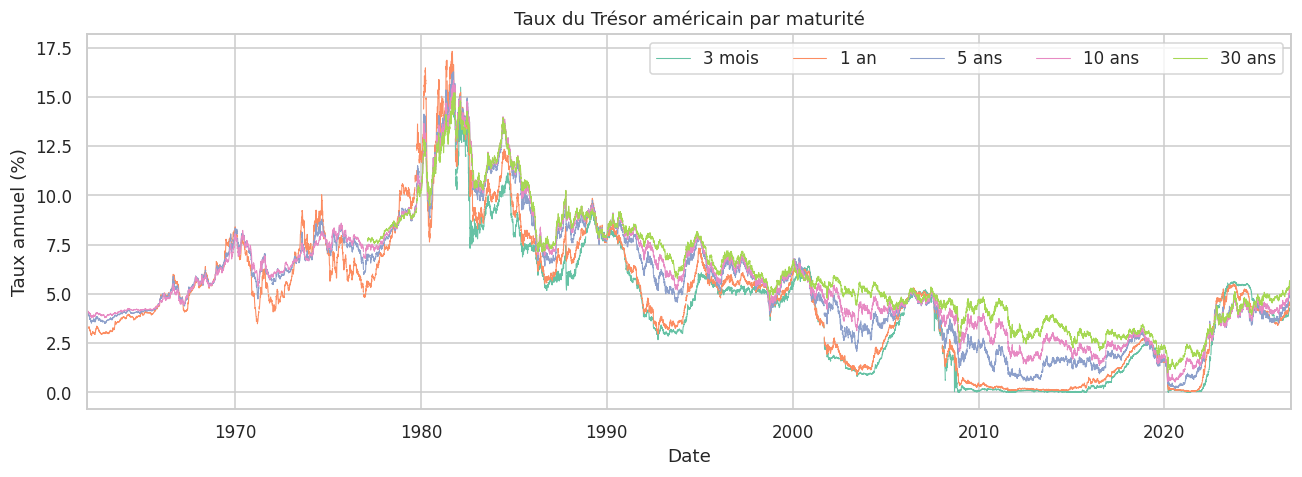

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
df.plot(ax=ax, linewidth=0.7)
ax.set(title="Taux du Trésor américain par maturité", xlabel="Date", ylabel="Taux annuel (%)")
ax.legend(MATURITES, ncol=5)
plt.tight_layout()
plt.show()
plt.close(fig)

### 4.2 Courbes de taux à plusieurs dates

Une courbe relie, pour une même date, les taux aux maturités. Une hausse parallèle correspond à un mouvement de niveau ; un changement de l'écart court-long correspond à un mouvement de pente. Les positions sur l'axe horizontal ci-dessous sont des catégories ordonnées, pas des distances proportionnelles aux années.

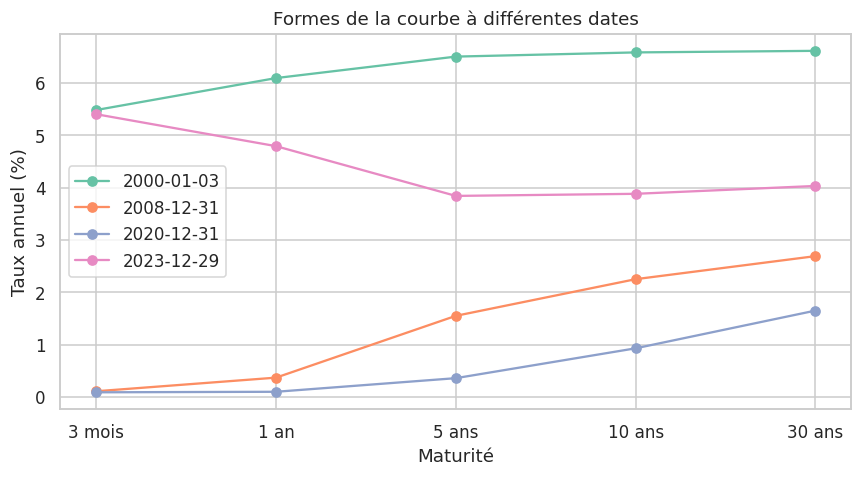

In [5]:
complets_exploration = df.dropna()
dates_voulues = ["2000-01-03", "2008-12-31", "2020-12-31", "2023-12-29"]
fig, ax = plt.subplots(figsize=(8, 4.5))
for d in dates_voulues:
    disponibles = complets_exploration.loc[:d]
    if len(disponibles):
        jour = disponibles.index[-1]
        ax.plot(MATURITES, disponibles.iloc[-1], marker="o", label=str(jour.date()))
ax.set(title="Formes de la courbe à différentes dates", xlabel="Maturité", ylabel="Taux annuel (%)")
ax.legend()
plt.tight_layout()
plt.show()
plt.close(fig)

## 5. Préparation des données

### 5.1 Alignement et variations journalières

Pour chaque maturité $j$, la variation est :

$$\Delta y_{t,j}^{pb}=100\,(y_{t,j}-y_{t-1,j}).$$

Les taux d'origine sont des nombres comme `4.17` pour 4,17 %. Une variation de `4.17` à `4.22` vaut **+5 points de base**, pas +5 % de rendement relatif.

Étapes : trier les dates, filtrer explicitement l'intervalle litigieux, conserver les observations complètes, puis calculer les différences. Une différence traversant plus de sept jours calendaires est exclue : cette règle évite notamment de relier 2002 à 2006. Les différences après un week-end restent des variations entre deux séances disponibles, sans division par le nombre de jours.

In [6]:
def preparer_variations(taux_bruts, exclure_intervalle=True):
    taux = taux_bruts.copy()
    if exclure_intervalle:
        intervalle = (taux.index >= "2002-02-18") & (taux.index < "2006-02-09")
        taux.loc[intervalle, "DGS30"] = np.nan
    taux = taux.dropna(subset=SERIES)
    ecart_jours = taux.index.to_series().diff().dt.days
    variations = taux.diff().mul(100)
    variations = variations.loc[ecart_jours.le(7)].dropna()
    assert variations.index.is_monotonic_increasing
    assert not variations.isna().any().any()
    assert np.isfinite(variations.to_numpy()).all()
    return taux, variations

taux, X = preparer_variations(df, RETIRER_INTERVALLE_DOCUMENTE)
print("Période des niveaux alignés :", taux.index.min().date(), "à", taux.index.max().date())
print("Niveaux complets :", len(taux), "| Variations :", len(X))
print("\nPremières variations (pb) :")
print(X.head(3).round(2).to_string())
print("\nÉcarts-types des variations (pb) :")
print(X.std().round(2).to_string())

Période des niveaux alignés : 1981-09-01 à 2026-11-05
Niveaux complets : 10301 | Variations : 10299

Premières variations (pb) :
            DGS3MO  DGS1  DGS5  DGS10  DGS30
Date                                        
1981-09-02   -36.0  10.0  -3.0   -1.0    0.0
1981-09-03    31.0  15.0   5.0    8.0   12.0
1981-09-04   -32.0  -7.0   3.0    3.0    2.0

Écarts-types des variations (pb) :
DGS3MO    7.48
DGS1      6.72
DGS5      7.02
DGS10     6.69
DGS30     6.19


**Sortie obtenue sur les fichiers fournis :**

```text
Période des niveaux alignés : 1981-09-01 à 2026-11-05
Niveaux complets : 10301 | Variations : 10299

Premières variations (pb) :
            DGS3MO  DGS1  DGS5  DGS10  DGS30
Date                                        
1981-09-02   -36.0  10.0  -3.0   -1.0    0.0
1981-09-03    31.0  15.0   5.0    8.0   12.0
1981-09-04   -32.0  -7.0   3.0    3.0    2.0

Écarts-types des variations (pb) :
DGS3MO    7.48
DGS1      6.72
DGS5      7.02
DGS10     6.69
DGS30     6.19
```


### 5.2 Distributions et corrélations des variations

Nous conservons les mouvements extrêmes : ils peuvent correspondre aux séances qui structurent le risque. Les supprimer sans justification modifierait la question étudiée. Une vérification ultérieure de leur provenance reste nécessaire avant une utilisation professionnelle.

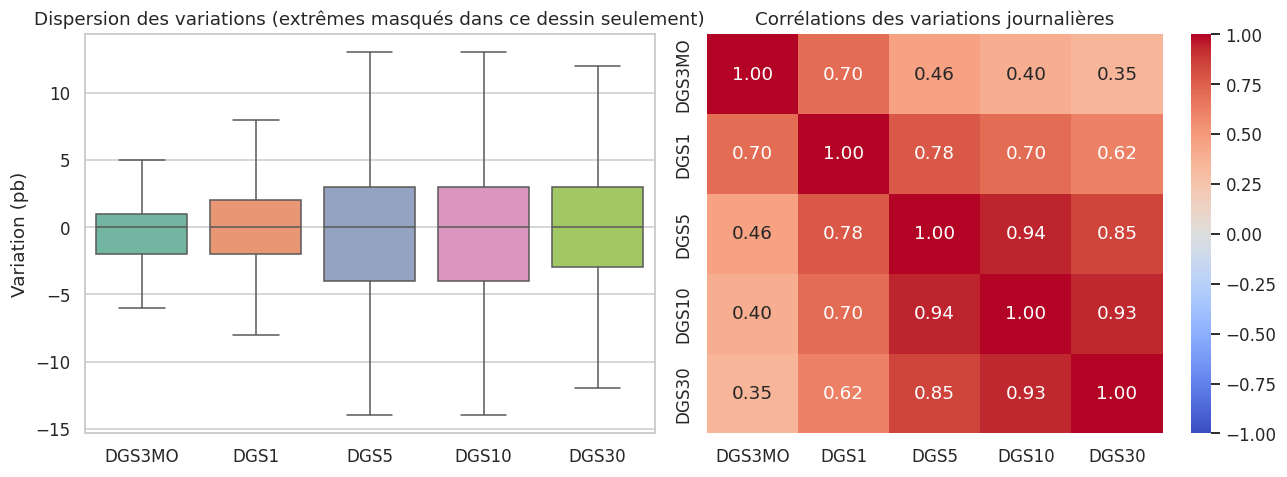

Corrélations :
        DGS3MO   DGS1   DGS5  DGS10  DGS30
DGS3MO   1.000  0.702  0.458  0.397  0.351
DGS1     0.702  1.000  0.779  0.699  0.617
DGS5     0.458  0.779  1.000  0.939  0.846
DGS10    0.397  0.699  0.939  1.000  0.935
DGS30    0.351  0.617  0.846  0.935  1.000


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=X, ax=axes[0], showfliers=False)
axes[0].set(title="Dispersion des variations (extrêmes masqués dans ce dessin seulement)", ylabel="Variation (pb)")
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Corrélations des variations journalières")
plt.tight_layout()
plt.show()
plt.close(fig)
print("Corrélations :")
print(X.corr().round(3).to_string())

**Sortie obtenue sur les fichiers fournis :**

```text
Corrélations :
        DGS3MO   DGS1   DGS5  DGS10  DGS30
DGS3MO   1.000  0.702  0.458  0.397  0.351
DGS1     0.702  1.000  0.779  0.699  0.617
DGS5     0.458  0.779  1.000  0.939  0.846
DGS10    0.397  0.699  0.939  1.000  0.935
DGS30    0.351  0.617  0.846  0.935  1.000
```


**Lecture.** Des corrélations positives indiquent des mouvements souvent communs. Elles motivent une réduction de dimension, mais ne prouvent pas que trois axes suffiront : il faut mesurer la variance conservée.

### 5.3 Centrage, standardisation et découpage temporel

L'analyse principale est une **ACP sur la covariance des variations en points de base**, centrées mais non réduites. Toutes les variables ont la même unité ; leur volatilité relative fait partie du phénomène financier. `PCA` effectue automatiquement le centrage.

Une ACP standardisée répond à une autre question : chaque maturité reçoit une variance initiale égale à 1. Nous l'utiliserons comme contrôle de sensibilité, sans la confondre avec la méthode principale.

Nous séparons chronologiquement les données : 80 % des dates pour l'entraînement, 20 % pour le test. Aucun mélange aléatoire des séances. La comparaison hors échantillon apprend ses moyennes et ses axes sur l'entraînement uniquement. Les graphiques descriptifs de l'ensemble de la période ne constituent pas un test prédictif.

In [8]:
frontiere = int(0.80 * len(X))
X_train, X_test = X.iloc[:frontiere], X.iloc[frontiere:]
print("Entraînement :", X_train.index.min().date(), "à", X_train.index.max().date(), "—", len(X_train), "dates")
print("Test :", X_test.index.min().date(), "à", X_test.index.max().date(), "—", len(X_test), "dates")

Entraînement : 1981-09-02 à 2018-08-08 — 8239 dates
Test : 2018-08-09 à 2026-11-05 — 2060 dates


**Sortie obtenue sur les fichiers fournis :**

```text
Entraînement : 1981-09-02 à 2018-08-08 — 8239 dates
Test : 2018-08-09 à 2026-11-05 — 2060 dates
```


## 6. Entraînement et comparaison des modèles

### 6.1 Référence : ACP à une composante

La référence résume les cinq variations par un seul facteur. L'ACP à trois composantes est utile si elle améliore nettement la reconstruction. Une ACP complète à cinq composantes sert de contrôle : elle doit reconstruire les données à l'arrondi numérique près.

Pour la composante $k$, la part de variance expliquée est :

$$r_k=\frac{\lambda_k}{\sum_{j=1}^{5}\lambda_j}.$$

Nous définissons ici « l'essentiel » comme **au moins 95 % de variance expliquée cumulée**. Ce seuil est une convention de travail, pas une loi financière. Nous examinerons aussi la performance hors échantillon et les sous-périodes.

Composante  Variance (%)  Cumul (%)
       CP1        73.542     73.542
       CP2        19.153     92.695
       CP3         4.637     97.333
       CP4         2.080     99.413
       CP5         0.587    100.000
Nombre de composantes pour 95 % : 3


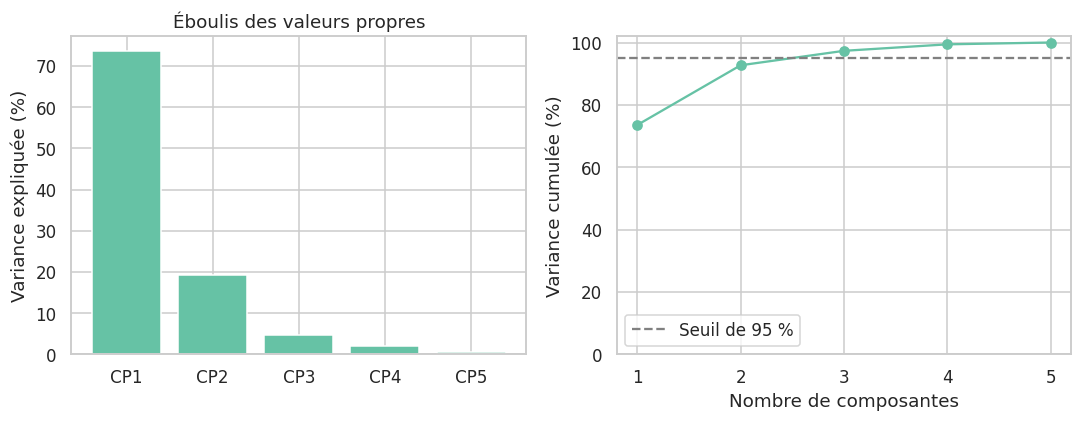

In [9]:
acp_complete = PCA(n_components=5, svd_solver="full").fit(X)
variance = pd.DataFrame({
    "Composante": [f"CP{i}" for i in range(1, 6)],
    "Variance (%)": 100 * acp_complete.explained_variance_ratio_,
    "Cumul (%)": 100 * np.cumsum(acp_complete.explained_variance_ratio_),
})
print(variance.round(3).to_string(index=False))
nb_95 = int(np.searchsorted(np.cumsum(acp_complete.explained_variance_ratio_), SEUIL) + 1)
print("Nombre de composantes pour 95 % :", nb_95)
assert np.allclose(acp_complete.inverse_transform(acp_complete.transform(X)), X)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(variance["Composante"], variance["Variance (%)"])
axes[0].set(title="Éboulis des valeurs propres", ylabel="Variance expliquée (%)")
axes[1].plot(range(1, 6), variance["Cumul (%)"], "o-")
axes[1].axhline(100 * SEUIL, color="grey", linestyle="--", label="Seuil de 95 %")
axes[1].set(xticks=range(1, 6), xlabel="Nombre de composantes", ylabel="Variance cumulée (%)", ylim=(0, 102))
axes[1].legend()
plt.tight_layout()
plt.show()
plt.close(fig)

**Sortie obtenue sur les fichiers fournis :**

```text
Composante  Variance (%)  Cumul (%)
       CP1        73.542     73.542
       CP2        19.153     92.695
       CP3         4.637     97.333
       CP4         2.080     99.413
       CP5         0.587    100.000
Nombre de composantes pour 95 % : 3
```


### 6.2 Comparaison avec l'analyse factorielle

L'ACP maximise la variance conservée. L'analyse factorielle utilise le modèle $x_t=\mu+\Lambda f_t+\varepsilon_t$, où les facteurs communs sont séparés d'un bruit spécifique à chaque maturité. Sa reconstruction utilise les scores estimés et la matrice des charges ; elle ne possède pas le même indicateur de variance expliquée ordonnée que l'ACP.

**Limite avec cinq maturités.** Pour $p=5$ variables et $q$ facteurs, le nombre de paramètres de covariance, après prise en compte des rotations, est $pq+p-q(q-1)/2$. La covariance observée offre $p(p+1)/2=15$ éléments distincts. Deux facteurs utilisent 14 paramètres ; trois en utilisent 17. L'analyse factorielle à trois facteurs est donc sous-identifiée sans contraintes supplémentaires. Le logiciel peut produire une solution numérique, mais celle-ci ne valide pas une structure unique de trois facteurs.

Nous présentons FA à deux facteurs comme comparaison plus parcimonieuse et FA à trois facteurs comme **contrôle exploratoire** imposé par la question. Ni une faible erreur ni la convergence de l'algorithme ne résolvent ce problème d'identification.

In [10]:
modeles = {
    "ACP 1 (référence)": PCA(n_components=1, svd_solver="full"),
    "ACP 3": PCA(n_components=3, svd_solver="full"),
    "FA 2": FactorAnalysis(n_components=2, svd_method="lapack", max_iter=3000, tol=0.001, random_state=42),
    "FA 3 (exploratoire)": FactorAnalysis(n_components=3, svd_method="lapack", max_iter=3000, tol=0.001, random_state=42),
}

def reconstruire(modele, donnees):
    scores = modele.transform(donnees)
    if isinstance(modele, PCA):
        return modele.inverse_transform(scores)
    return scores @ modele.components_ + modele.mean_

def mesurer(original, reconstruction, centre_reference):
    valeurs = np.asarray(original)
    erreurs = valeurs - reconstruction
    rmse = np.sqrt(np.mean(erreurs ** 2))
    denominateur = np.sum((valeurs - np.asarray(centre_reference)) ** 2)
    conservation = 1 - np.sum(erreurs ** 2) / denominateur
    return rmse, conservation

resultats = []
for nom, modele in modeles.items():
    modele.fit(X_train)
    for partition, donnees in [("Entraînement", X_train), ("Test", X_test)]:
        rmse, conservation = mesurer(donnees, reconstruire(modele, donnees), X_train.mean())
        resultats.append({"Modèle": nom, "Partition": partition,
                          "RMSE (pb)": rmse, "Énergie conservée (%)": 100 * conservation})
comparaison = pd.DataFrame(resultats)
print(comparaison.round(3).to_string(index=False))
for nom, modele in modeles.items():
    if isinstance(modele, FactorAnalysis):
        print(nom, "— itérations :", modele.n_iter_)

             Modèle    Partition  RMSE (pb)  Énergie conservée (%)
  ACP 1 (référence) Entraînement      3.680                 73.907
  ACP 1 (référence)         Test      2.796                 69.598
              ACP 3 Entraînement      1.154                 97.434
              ACP 3         Test      0.963                 96.392
               FA 2 Entraînement      2.835                 84.520
               FA 2         Test      2.028                 84.004
FA 3 (exploratoire) Entraînement      1.751                 94.096
FA 3 (exploratoire)         Test      1.419                 92.172
FA 2 — itérations : 2623
FA 3 (exploratoire) — itérations : 944


**Sortie obtenue sur les fichiers fournis :**

```text
Modèle    Partition  RMSE (pb)  Énergie conservée (%)
  ACP 1 (référence) Entraînement      3.680                 73.907
  ACP 1 (référence)         Test      2.796                 69.598
              ACP 3 Entraînement      1.154                 97.434
              ACP 3         Test      0.963                 96.392
               FA 2 Entraînement      2.835                 84.520
               FA 2         Test      2.028                 84.004
FA 3 (exploratoire) Entraînement      1.751                 94.096
FA 3 (exploratoire)         Test      1.419                 92.172
FA 2 — itérations : 2623
FA 3 (exploratoire) — itérations : 944
```


**Lecture.** La RMSE est calculée sur toutes les dates et maturités, en points de base. Plus elle est basse, plus les variations sont fidèlement reconstruites. L'« énergie conservée » vaut $1-\sum(x-\hat x)^2/\sum(x-\bar x_{train})^2$ : c'est une métrique commune de reconstruction, pas un taux officiel de variance expliquée pour FA. Hors échantillon, elle peut être négative. L'ACP est conçue pour minimiser l'erreur quadratique sur son échantillon d'ajustement ; cela ne la rend pas supérieure pour toute question statistique.

## 7. Évaluation finale sur le jeu de test

Le test mesure la capacité d'axes appris sur le passé à représenter une période plus récente. Il ne mesure pas une prévision du lendemain : les cinq variations du jour sont observées pour calculer ses scores.

Nous comparons particulièrement ACP 1 et ACP 3, sans choisir le nombre de facteurs après avoir optimisé sur le test.

In [11]:
test = comparaison.query("Partition == 'Test'").set_index("Modèle")
rmse_1 = test.loc["ACP 1 (référence)", "RMSE (pb)"]
rmse_3 = test.loc["ACP 3", "RMSE (pb)"]
gain = 100 * (1 - rmse_3 / rmse_1)
print(f"Réduction relative de la RMSE test, ACP 3 contre ACP 1 : {gain:.2f} %")
print("\nRMSE test par maturité (pb), ACP 3 :")
erreurs_test = X_test.to_numpy() - reconstruire(modeles["ACP 3"], X_test)
print(pd.Series(np.sqrt((erreurs_test ** 2).mean(axis=0)), index=SERIES).round(3).to_string())

Réduction relative de la RMSE test, ACP 3 contre ACP 1 : 65.55 %

RMSE test par maturité (pb), ACP 3 :
DGS3MO    0.196
DGS1      0.761
DGS5      1.419
DGS10     0.606
DGS30     1.282


**Sortie obtenue sur les fichiers fournis :**

```text
Réduction relative de la RMSE test, ACP 3 contre ACP 1 : 65.55 %

RMSE test par maturité (pb), ACP 3 :
DGS3MO    0.196
DGS1      0.761
DGS5      1.419
DGS10     0.606
DGS30     1.282
```


**Lecture.** La moyenne globale peut cacher une maturité mal représentée. Les erreurs par maturité permettent de le repérer. Même avec 95 % de variance globale conservée, certaines séances extrêmes ou certains segments peuvent être moins bien décrits.

## 8. Interprétation des trois premiers facteurs

### 8.1 Coefficients des axes et scores journaliers

Pour une ACP centrée, le score du jour est $f_{t,k}=\sum_j (\Delta y_{t,j}-\overline{\Delta y_j})v_{k,j}$, où $v_k$ est un axe unitaire. Les **coefficients des axes** décrivent le mouvement entre maturités ; les **scores** décrivent son intensité au fil du temps. Ces coefficients ne sont pas automatiquement des corrélations variable-composante.

| Profil observé sur les maturités | Interprétation possible |
|---|---|
| Coefficients de même signe, idéalement assez homogènes | Niveau, ou mouvement commun approximativement parallèle |
| Opposition entre maturités courtes et longues | Pente |
| Opposition entre le milieu et les extrémités | Courbure |

Le signe d'un axe est arbitraire : inverser simultanément ses coefficients et ses scores conserve exactement la même reconstruction. Nous orientons chaque axe pour que son coefficient le plus grand en valeur absolue soit positif, uniquement pour faciliter la lecture. Les noms niveau/pente/courbure restent des hypothèses à confronter au profil réel, et non des étiquettes garanties par l'algorithme.

Coefficients des axes unitaires :
           CP1     CP2     CP3
3 mois  0.3822  0.8001 -0.4443
1 an    0.4538  0.2597  0.7345
5 ans   0.5055 -0.2394  0.1979
10 ans  0.4734 -0.3383 -0.1760
30 ans  0.4103 -0.3474 -0.4393

Corrélations scores / profils économiques :
                        CP1    CP2    CP3
Niveau moyen          0.999  0.031 -0.014
Pente 30a-3m          0.047 -0.977  0.002
Courbure 2x5a-3m-30a  0.319 -0.693  0.469


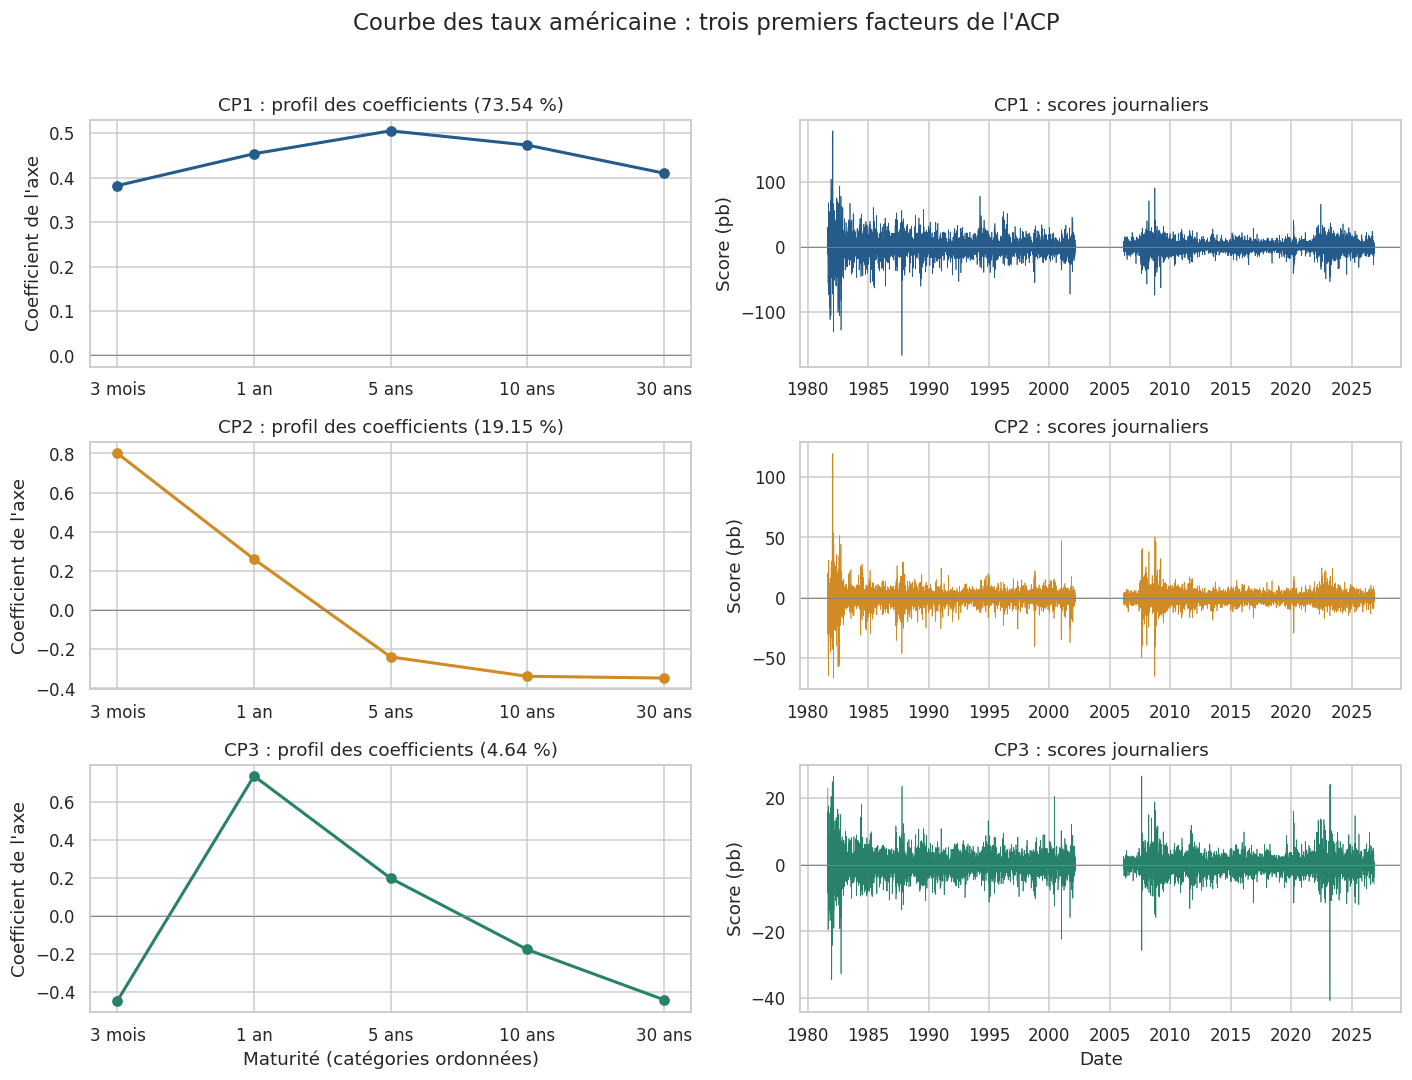

In [12]:
acp_3 = PCA(n_components=3, svd_solver="full").fit(X)
poids = acp_3.components_.copy()
scores = acp_3.transform(X)
for k in range(3):
    j = np.argmax(np.abs(poids[k]))
    signe = 1 if poids[k, j] >= 0 else -1
    poids[k] *= signe
    scores[:, k] *= signe

charges = pd.DataFrame(poids.T, index=MATURITES, columns=["CP1", "CP2", "CP3"])
facteurs = pd.DataFrame(scores, index=X.index, columns=charges.columns)
print("Coefficients des axes unitaires :")
print(charges.round(4).to_string())

# Trois profils économiques simples, à interpréter avec prudence.
proxies = pd.DataFrame({
    "Niveau moyen": X.mean(axis=1),
    "Pente 30a-3m": X["DGS30"] - X["DGS3MO"],
    "Courbure 2x5a-3m-30a": 2 * X["DGS5"] - X["DGS3MO"] - X["DGS30"],
})
corr_proxies = pd.DataFrame({c: proxies.corrwith(facteurs[c]) for c in facteurs})
print("\nCorrélations scores / profils économiques :")
print(corr_proxies.round(3).to_string())

fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for k in range(3):
    couleur = ["#245B8A", "#D18B25", "#28816B"][k]
    part = 100 * acp_3.explained_variance_ratio_[k]
    axes[k, 0].plot(MATURITES, poids[k], "o-", color=couleur, linewidth=2)
    axes[k, 0].axhline(0, color="grey", linewidth=0.6)
    axes[k, 0].set(title=f"CP{k+1} : profil des coefficients ({part:.2f} %)", ylabel="Coefficient de l'axe")
    # Une courbe par bloc continu pour ne pas traverser l'interruption historique.
    groupes = facteurs.index.to_series().diff().dt.days.gt(7).cumsum()
    for _, bloc in facteurs.groupby(groupes):
        axes[k, 1].plot(bloc.index, bloc.iloc[:, k], color=couleur, linewidth=0.45)
    axes[k, 1].axhline(0, color="grey", linewidth=0.6)
    axes[k, 1].set(title=f"CP{k+1} : scores journaliers", ylabel="Score (pb)")
axes[-1, 0].set_xlabel("Maturité (catégories ordonnées)")
axes[-1, 1].set_xlabel("Date")
fig.suptitle("Courbe des taux américaine : trois premiers facteurs de l'ACP", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("F20_trois_facteurs.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

**Sortie obtenue sur les fichiers fournis :**

```text
Coefficients des axes unitaires :
           CP1     CP2     CP3
3 mois  0.3822  0.8001 -0.4443
1 an    0.4538  0.2597  0.7345
5 ans   0.5055 -0.2394  0.1979
10 ans  0.4734 -0.3383 -0.1760
30 ans  0.4103 -0.3474 -0.4393

Corrélations scores / profils économiques :
                        CP1    CP2    CP3
Niveau moyen          0.999  0.031 -0.014
Pente 30a-3m          0.047 -0.977  0.002
Courbure 2x5a-3m-30a  0.319 -0.693  0.469
```


![Profils et scores des trois premières composantes](attachment:F20_trois_facteurs.png)

**Lecture de la figure.** Les panneaux de gauche montrent les profils par maturité ; ceux de droite montrent les scores journaliers. La coupure de 2002–2006 n’est pas reliée par un trait. Une grande amplitude d’un score indique une séance inhabituelle selon cet axe, sans en identifier la cause.


### 8.2 Stabilité selon les sous-périodes

Nous réestimons l'ACP séparément sur plusieurs fenêtres. Les étiquettes temporelles ne constituent pas une preuve d'effet causal de la politique monétaire. Les axes peuvent changer d'ordre ou de signe : comparer seulement leurs coefficients signés peut être trompeur.

Outre les parts de variance, nous calculons le plus grand **angle principal** entre le sous-espace des trois axes d'une fenêtre et celui de la période entière. Un angle proche de zéro indique des sous-espaces similaires. Cet indicateur est descriptif ; il ne s'agit pas d'un test de stabilité formel.

  Période    N  CP1 (%)  CP2 (%)  CP3 (%)  Cumul 3 (%)  Angle max (°)
1981-2001 5078    77.13    17.02     3.68        97.83           7.09
2006-2008  725    65.47    28.32     4.17        97.97           4.51
2009-2019 2751    87.25     6.46     3.47        97.18          52.25
2020-2021  502    80.44    10.73     6.28        97.45          55.05
 2022-fin 1211    78.90    12.50     6.06        97.47           6.91


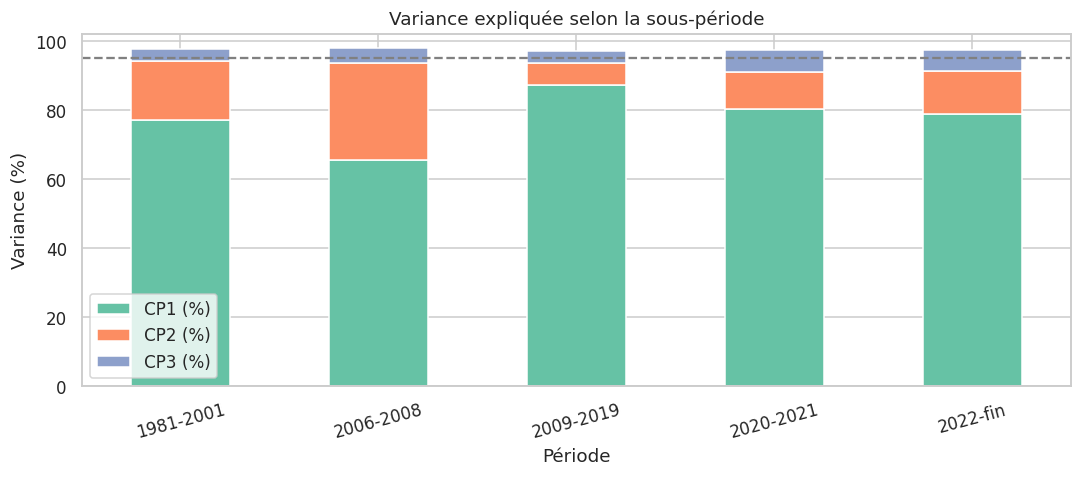

In [13]:
periodes = {
    "1981-2001": ("1981-01-01", "2001-12-31"),
    "2006-2008": ("2006-02-09", "2008-12-31"),
    "2009-2019": ("2009-01-01", "2019-12-31"),
    "2020-2021": ("2020-01-01", "2021-12-31"),
    "2022-fin": ("2022-01-01", str(FIN_ETUDE.date())),
}
stabilite = []
for nom, (debut, fin) in periodes.items():
    bloc = X.loc[debut:fin]
    if len(bloc) < 30:
        continue
    modele = PCA(n_components=5, svd_solver="full").fit(bloc)
    ratios = modele.explained_variance_ratio_
    angle = np.degrees(subspace_angles(acp_3.components_.T, modele.components_[:3].T)).max()
    stabilite.append({"Période": nom, "N": len(bloc), "CP1 (%)": 100 * ratios[0],
                      "CP2 (%)": 100 * ratios[1], "CP3 (%)": 100 * ratios[2],
                      "Cumul 3 (%)": 100 * ratios[:3].sum(), "Angle max (°)": angle})
stabilite = pd.DataFrame(stabilite)
print(stabilite.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
stabilite.set_index("Période")[["CP1 (%)", "CP2 (%)", "CP3 (%)"]].plot.bar(stacked=True, ax=ax)
ax.axhline(100 * SEUIL, color="grey", linestyle="--")
ax.set(title="Variance expliquée selon la sous-période", ylabel="Variance (%)", ylim=(0, 102))
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()
plt.close(fig)

**Sortie obtenue sur les fichiers fournis :**

```text
Période    N  CP1 (%)  CP2 (%)  CP3 (%)  Cumul 3 (%)  Angle max (°)
1981-2001 5078    77.13    17.02     3.68        97.83           7.09
2006-2008  725    65.47    28.32     4.17        97.97           4.51
2009-2019 2751    87.25     6.46     3.47        97.18          52.25
2020-2021  502    80.44    10.73     6.28        97.45          55.05
 2022-fin 1211    78.90    12.50     6.06        97.47           6.91
```


### 8.3 Sensibilité à la standardisation et à l'intervalle DGS30

Une forte variance expliquée qui n'apparaît que pour un seul choix de traitement doit être présentée avec cette limite. L'analyse suivante change une décision à la fois. La variante conservant l'intervalle litigieux est un contrôle de sensibilité, pas une certification des données de 2002–2006.

In [14]:
scaler = StandardScaler()
Z = scaler.fit_transform(X)  # descriptif, pas le test hors échantillon
acp_standardisee = PCA(n_components=5, svd_solver="full").fit(Z)
_, X_sans_filtre = preparer_variations(df, exclure_intervalle=False)
acp_sans_filtre = PCA(n_components=5, svd_solver="full").fit(X_sans_filtre)
sensibilite = pd.DataFrame([
    {"Variante": "Covariance, intervalle exclu (principale)", "N": len(X),
     "Cumul 1 (%)": 100 * acp_complete.explained_variance_ratio_[0],
     "Cumul 3 (%)": 100 * acp_complete.explained_variance_ratio_[:3].sum()},
    {"Variante": "Standardisée, intervalle exclu", "N": len(X),
     "Cumul 1 (%)": 100 * acp_standardisee.explained_variance_ratio_[0],
     "Cumul 3 (%)": 100 * acp_standardisee.explained_variance_ratio_[:3].sum()},
    {"Variante": "Covariance, toutes valeurs reçues", "N": len(X_sans_filtre),
     "Cumul 1 (%)": 100 * acp_sans_filtre.explained_variance_ratio_[0],
     "Cumul 3 (%)": 100 * acp_sans_filtre.explained_variance_ratio_[:3].sum()},
])
print(sensibilite.round(3).to_string(index=False))

                                 Variante     N  Cumul 1 (%)  Cumul 3 (%)
Covariance, intervalle exclu (principale) 10299       73.542       97.333
           Standardisée, intervalle exclu 10299       74.870       97.212
        Covariance, toutes valeurs reçues 11294       73.563       97.180


**Sortie obtenue sur les fichiers fournis :**

```text
Variante     N  Cumul 1 (%)  Cumul 3 (%)
Covariance, intervalle exclu (principale) 10299       73.542       97.333
           Standardisée, intervalle exclu 10299       74.870       97.212
        Covariance, toutes valeurs reçues 11294       73.563       97.180
```


## 9. Représenter une nouvelle observation

À la place de la prédiction d'une espèce dans le TP modèle, nous projetons une **variation de courbe fictive** sur les axes appris. L'ACP à trois composantes utilisée ici est celle entraînée dans la section 6 sur le passé, sans réajustement sur cette nouvelle observation.

In [15]:
nouveau = pd.DataFrame([[5.0, 4.0, 2.0, 1.0, 0.0]], columns=SERIES)
modele_passe = modeles["ACP 3"]
scores_nouveaux = modele_passe.transform(nouveau)
reconstruction = reconstruire(modele_passe, nouveau)
illustration = pd.DataFrame({
    "Variation observée (pb)": nouveau.iloc[0].to_numpy(),
    "Reconstruction ACP 3 (pb)": reconstruction[0],
    "Résidu (pb)": nouveau.iloc[0].to_numpy() - reconstruction[0],
}, index=MATURITES)
print("Scores de l'observation fictive :", np.round(scores_nouveaux[0], 3))
print(illustration.round(3).to_string())

Scores de l'observation fictive : [5.777 4.036 1.026]
        Variation observée (pb)  Reconstruction ACP 3 (pb)  Résidu (pb)
3 mois                      5.0                      4.958        0.042
1 an                        4.0                      4.155       -0.155
5 ans                       2.0                      1.757        0.243
10 ans                      1.0                      0.867        0.133
30 ans                      0.0                      0.315       -0.315


**Sortie obtenue sur les fichiers fournis :**

```text
Scores de l'observation fictive : [5.777 4.036 1.026]
        Variation observée (pb)  Reconstruction ACP 3 (pb)  Résidu (pb)
3 mois                      5.0                      4.958        0.042
1 an                        4.0                      4.155       -0.155
5 ans                       2.0                      1.757        0.243
10 ans                      1.0                      0.867        0.133
30 ans                      0.0                      0.315       -0.315
```


**Lecture.** Le court terme monte davantage que le long terme : l'écart long-court se réduit. Le modèle traduit ce mouvement en trois scores, puis reconstruit cinq variations. Le résidu correspond à l'information perdue par la réduction de dimension.

## 10. Synthèse, conclusion et questions

### 10.1 Conclusion calculée sur les fichiers fournis


L'analyse principale utilise **10,299 variations complètes**, du **02/09/1981** au **05/11/2026**, après exclusion explicite de l'intervalle DGS30 documenté et de la variation traversant cette coupure.

- La référence à un facteur explique **73.54 %** de la variance sur la période entière.
- Les trois premiers facteurs expliquent ensemble **97.33 %**. Le seuil de 95 % est **atteint**.
- L'ACP à trois composantes réduit la RMSE de reconstruction sur le test de **65.55 %** par rapport à l'ACP à une composante.
- Selon la sous-période, le cumul à trois facteurs varie entre **97.18 %** et **97.97 %**. **5 fenêtres sur 5** franchissent 95 %.

**Réponse à la question.** Oui, au seuil descriptif de 95 % retenu ici, trois axes résument l’essentiel des variations globales sur cet échantillon. Cette conclusion porte sur les cinq maturités retenues et les données reçues. Sa portée dépend des sous-périodes, de la mise à l'échelle et de la vérification de la provenance des observations.

La stabilité du pourcentage conservé ne signifie pas que les facteurs restent identiques : les angles maximaux dépassent 50° sur 2009–2019 et 2020–2021. Trois dimensions restent efficaces, mais leur orientation dans l’espace des maturités change sensiblement sur ces fenêtres.


### 10.2 Interprétation observée des axes


**CP1** : parmi les trois profils économiques proposés, la corrélation la plus forte en valeur absolue est avec **Niveau moyen** (+0.999). Ce rapprochement aide la lecture, mais ne remplace pas l’examen de ses coefficients dans la section 8.


**CP2** : parmi les trois profils économiques proposés, la corrélation la plus forte en valeur absolue est avec **Pente 30a-3m** (-0.977). Ce rapprochement aide la lecture, mais ne remplace pas l’examen de ses coefficients dans la section 8.


**CP3** : parmi les trois profils économiques proposés, la corrélation la plus forte en valeur absolue est avec **Courbure 2x5a-3m-30a** (+0.469). Ce rapprochement aide la lecture, mais ne remplace pas l’examen de ses coefficients dans la section 8.

**Lecture économique des profils.** CP1 a cinq coefficients positifs, assez proches : elle s’interprète comme un **niveau commun**, approximativement parallèle. CP2 oppose les maturités courtes aux maturités longues : elle décrit la **pente**. CP3 oppose les deux extrémités au segment 1–5 ans, avec une bosse particulièrement forte à 1 an : elle évoque une **courbure**, mais pas une courbure symétrique centrée sur 5 ans. Sa corrélation seulement modérée avec le proxy choisi confirme que cette troisième étiquette est moins nette que les deux premières.


### 10.3 Ce qu'il faut retenir

1. **Type d'apprentissage :** non supervisé, réduction de dimension, sans cible connue.
2. **Démarche :** explorer les sources, aligner les dates, traiter explicitement les coupures, calculer les variations, ajuster puis comparer les modèles.
3. **Référence :** une ACP à une composante, contre laquelle quantifier le gain de trois composantes.
4. **Évaluation :** variance expliquée, reconstruction globale et par maturité, test chronologique et sensibilité temporelle.
5. **Interprétation :** niveau, pente et courbure sont des profils économiques possibles. Les signes, l'ordre et les mélanges d'axes peuvent varier.
6. **Analyse factorielle :** distinction entre mouvement commun et bruit spécifique ; l'estimation exploratoire à trois facteurs n'est pas structurellement identifiée avec seulement cinq variables sans contraintes supplémentaires.

### 10.4 Limites et pistes de vérification

- Le seuil de 95 % est un choix analytique. La variance résiduelle peut encore compter pour une couverture de risque précise.
- Les dates supprimées, les données extrêmes, les révisions FRED et l'ambiguïté 2002–2006 doivent être documentées.
- Les fenêtres proposées décrivent des époques ; elles n'identifient pas à elles seules l'effet causal d'une décision de politique monétaire.
- L'ACP est linéaire. La variance expliquée ne garantit ni une distribution normale, ni une stabilité future, ni l'absence de risques extrêmes.
- Les scores dépendent d'une séance observée. Une étude de prévision nécessiterait une cible future, des données disponibles à la date de décision et une validation spécifique.

### 10.5 Questions d'application

1. Pourquoi une ACP directement sur les niveaux répond-elle à une autre question qu'une ACP sur leurs variations ?
2. Refaire l'étude avec deux et quatre composantes. Que gagne-t-on en variance conservée et en erreur de reconstruction ?
3. Remplacer le seuil de 95 % par 90 %, puis 99 %. Le nombre de composantes change-t-il ?
4. Comparer covariance et corrélation. Quelle maturité reçoit davantage de poids après standardisation ?
5. Dans quelle sous-période trois facteurs conservent-ils le moins de variance ? Quelle vérification supplémentaire serait nécessaire avant d'attribuer cela à une politique monétaire ?
6. Pourquoi inverser le signe d'un axe n'affecte-t-il pas sa reconstruction ? Vérifier ce point numériquement.
7. Pourquoi une analyse factorielle à trois facteurs n'est-elle pas identifiée ici ? Calculer le nombre de moments et de paramètres avec six maturités.
8. Le plus grand angle entre sous-espaces augmente-t-il nécessairement quand la variance conservée baisse ? Expliquer les deux notions.

> **Pour aller plus loin.** Ajouter une maturité (par exemple 2 ans), estimer l'ACP sur des fenêtres glissantes et aligner les axes entre fenêtres avant de comparer leurs profils. Préserver un échantillon de test final si des décisions de modèle sont prises sur une validation intermédiaire.

### 10.6 Sources et reproductibilité

- [FRED — DGS3MO](https://fred.stlouisfed.org/series/DGS3MO)
- [FRED — DGS1](https://fred.stlouisfed.org/series/DGS1)
- [FRED — DGS5](https://fred.stlouisfed.org/series/DGS5)
- [FRED — DGS10](https://fred.stlouisfed.org/series/DGS10)
- [FRED — DGS30 et note sur l'interruption](https://fred.stlouisfed.org/series/DGS30)
- [scikit-learn — PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [scikit-learn — FactorAnalysis](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.FactorAnalysis.html)

**Support pédagogique de référence :** `TP_apprentissage_automatique_manchots(1).ipynb`, fourni par l'utilisateur. Sa progression est reprise, avec adaptation des méthodes et des métriques au problème non supervisé.

**Données de cette exécution :** `F20_Donnees_FRED_ACP.xlsx`, feuille `Donnees_FRED`, et contrôle de cohérence avec `DGS30.csv`. Borne de l'étude : 9 novembre 2026. La dernière observation disponible dans les fichiers reçus est le 5 novembre 2026. Les sorties insérées sont celles de cette exécution, pas des valeurs théoriques attendues.

**Figure fournie :** `F20_trois_facteurs.png`. Conserver cette image dans le même dossier que ce document pour son affichage dans un lecteur Markdown. Les autres figures sont générées par les blocs Python correspondants.